<u/>**第二次模型拟合 / Second-time model regression**</u>

此笔记本将修改上一个模型当中的因子，然后进行第二次回归。这次回归将删除5个解释力弱的宏观因子以及政策事件dummies，并添加cpi，balance of trade，GDP作为新的宏观因子以及添加导致2015-2017年汇率大幅变化的政策事件dummies。在执行接下来的python代码之前，数据已经完成时间戳统一和数据清洗，并存放在```data/2_regression_monthly```。

This notebook will modify the factors in the previous model and then run a second regression. This regression will remove five macro factors with weak explanatory power and the policy event dummies, and add CPI, balance of trade, and GDP as new macro factors, as well as policy event dummies that caused large exchange rate fluctuations from 2015 to 2017. Before executing the following Python code, the data have already undergone timestamp unification and data cleaning and are stored in `data/2_regression_monthly`. 

**数据清洗的方式介绍 / Data-cleaning process intro.**

这里会处理三个宏观因子的数据： [source](data/source/) 当中的 [SLE_hcpi_m.csv](data/cleaned/SLE_hcpi_m.csv) ， [SLEGDP.csv](data/cleaned/SLEGDP.csv) ， [SLEBalanceofTrade.csv](data/cleaned/SLEBalanceofTrade.csv) 。

1. 截断数据的时间，2012 年 1 月至 2026 年 6 月。2012年之前的数据以及2026年6月之后的数据（如果有）删除。
2. 查找空缺的数据，如果要是数据出现了历史数据的空缺（最后一个发布数据与第一个发布的数据之间的空缺），则使用前一个数值（注意这里应该是数值，不是变化率）进行线性插值（也就是，前一个数据和后一个数据之间的插值除以时间，得到的每一个周期的变量）。如果数据最后部分空缺，保留最后的空缺（例如：最后只有到25年4月的数据，没有到26年的数据，则保留25年4月之后的空缺，不做任何填充）。
3. 对三个数据进行一阶差分：计算cpi的月度对数变化量，以及gdp和balance of trade的年度基期绝对值变化率：(本年值−上年值)/|上年值|。
4. 之后，对 [SLEGDP.csv](data/cleaned/SLEGDP.csv) 和 [SLEBalanceofTrade.csv](data/cleaned/SLEBalanceofTrade.csv) 两个年度数据进行月度化数据拆分，即年度数据拆成月度数据，然后每个月填充当年的变化值数据（例如，2026-01-01对应25年的数据，则25年1月-12月填充同一个数字，也就是24-25年变化值）。
5. 保留空缺数据的时间戳需要对齐 [USDSLE_monthly.csv](data/2_regression_monthly/USDSLE_monthly.csv) 当中的时间戳。
6. 所有数据存放在```data/2_regression_monthly```文件夹当中。


This section processes data for three macroeconomic factors: [SLE_hcpi_m.csv](data/cleaned/SLE_hcpi_m.csv), [SLEGDP.csv](data/cleaned/SLEGDP.csv), and [SLEBalanceofTrade.csv](data/cleaned/SLEBalanceofTrade.csv) in [source](data/source/).

1. Truncate the data to the period from January 2012 to June 2026. Delete data before 2012 and data after June 2026 (if any).
2. Search for missing data. If there is a historical gap in the data (a gap between the last published observation and the first published observation), fill it by linear interpolation using the adjacent values (note: interpolate the level, not the growth rate)—that is, interpolate between the previous and next observations over time to obtain a value for each period. If the missing data are at the end of the series, keep the trailing missing values (for example, if the last observation is only through April 2025 and there is no data through 2026, keep the missing values after April 2025 and do not fill them).
3. Take the first difference of the three series: calculate the monthly log change in CPI, and the annual base-period absolute-value change rate for GDP and balance of trade: \((current year value - previous year value)/|previous year value|\).
4. Next, perform monthly disaggregation of the two annual series, [SLEGDP.csv](data/cleaned/SLEGDP.csv) and [SLEBalanceofTrade.csv](data/cleaned/SLEBalanceofTrade.csv); that is, split the annual data into monthly data, and then fill each month with the change value for that year (for example, 2026-01-01 corresponds to 2025 data, so fill January–December 2025 with the same number, i.e., the 2024–25 change value).
5. For timestamps where missing data are retained, align them with the timestamps in [USDSLE_monthly.csv](data/2_regression_monthly/USDSLE_monthly.csv).
6. Store all data in the `data/2_regression_monthly` folder.

**政策与事件dummy整理/ Policy and Event Dummies**

| 变量 / Variable | 日期 / Date | 中文解释 | English explanation |
|---|---|---|---|
| `D_IMF_ECF_REVIEW_2015` | [2015-11-16](https://www.imf.org/en/news/articles/2015/09/14/01/49/pr15521) | IMF完成ECF第3、4次审查，批准4,614万美元拨款。 | The IMF completed the third and fourth ECF reviews and approved a $46.14 million disbursement. |
| `D_Brexit referendum_2016` | [2016-06-23](https://commonslibrary.parliament.uk/research-briefings/cbp-7960/) | 英国举行脱欧公投，脱欧阵营获胜。 | The UK held the Brexit referendum, with Leave winning. |
| `D_REDENOM_ANNOUNCE_2021` | [2021-08-11](https://bsl.gov.sl/Public%20Notice%20on%20Redenomination.pdf) | 央行宣布货币改值计划，1新里昂兑换1,000旧里昂。 | The central bank announced a redenomination plan: 1 new leone would equal 1,000 old leones. |
| `D_SDR_ALLOCATION_2021` | [2021-08-23](https://www.imf.org/en/topics/special-drawing-right/2021-sdr-allocation) | IMF分配约1.988亿特别提款权（SDR），补充塞拉利昂国际储备。 | The IMF allocated about SDR 198.8 million to supplement Sierra Leone’s international reserves. |
| `D_IMF_ECF_REVIEW_A_2023` | [2023-06-05](https://www.imf.org/en/news/articles/2023/06/05/pr23196-sierra-leone-imf-exec-board-completes-6th-7th-rev-under-ecf-arrangement) | IMF完成ECF第6、7次审查，批准2,070万美元拨款。 | The IMF completed the sixth and seventh ECF reviews and approved a $20.7 million disbursement. |
| `D_IMF_ECF_REVIEW_B_2023` | [2023-11-20](https://www.imf.org/en/news/articles/2023/11/20/pr23403-sierra-leone-imf-exec-board-completes-8th-final-rev-ecf-arr) | IMF完成ECF第8次暨最终审查，批准2,070万美元拨款。 | The IMF completed the eighth and final ECF review and approved a $20.7 million disbursement. |


针对三个新的宏观数据，下面将逐一进行重复的测试与回归，包括：
- 数据可视化图表，滚动统计值（rolling mean/std）
- 因子的基本统计数据（包括均值，中位数，最大值，最小值，标准差）
- ADF与KPSS检验，检测差分之后的数据是否仍然不平稳 

下一个笔记本将继续：
- 三个宏观数据，以及外汇储备，政府债务/GDP，一共五个数据之间的双因子相关性矩阵
- 五个宏观因子之间的VIF多重共线性检测
- 回归所有宏观因子与政策事件dummies，并检查hypothesis test
- 检查残差自相关，异方差，残差与汇率相关性

For the three new macro data series, the following repeated tests and regressions will be conducted one by one, including:

- Data visualization charts and rolling statistics (rolling mean/std)
- Basic statistics of the factors (including mean, median, maximum, minimum, and standard deviation)
- ADF and KPSS tests to check whether the differenced data remain non-stationary

The next notebook will continue: 
- Pairwise correlation matrix among the three macro data series plus foreign exchange reserves and government debt/GDP, five series in total
- VIF multicollinearity test among the five macro factors
- Regress all macro factors on policy event dummies and check hypothesis tests
- Check residual autocorrelation, heteroskedasticity, and correlation between residuals and the exchange rate

下面读取五个宏观因子，统一到训练期的月末日历，供图表、描述统计和单位根检验使用。训练期为 2012-01 至 2024-12；只读取日期和数值列；保留原有变化率单位及缺失值，不重新填补或差分。

The following five macro factors are read and unified to the end-of-month calendar of the training period for use in charting, descriptive statistics and unit root testing. The training period is from 2012-01 to 2024-12; only the date and value columns are read; the original change rate unit and missing values are retained, and no re-filling or differencing is performed.

In [1]:
# import packages
from pathlib import Path
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

In [ ]:
# set paths, files
DATA = Path("data/2_regression_monthly")
if not DATA.is_dir():
    DATA = Path("../data/2_regression_monthly")
TRAIN_START, TRAIN_END = "2012-01-31", "2024-12-31"
FILES = {
    "CPI": "headline_cpi_log_change_monthly.csv",
    "GDP growth change": "gdp_annual_pct_change_monthly.csv",
    "Trade balance change": "trade_balance_annual_pct_change_monthly.csv",
    "FX reserves": "fx_reserves_log_change_monthly.csv",
    "Government debt / GDP": "general_government_gross_debt_annual_change_pp_monthly.csv",
}
ANNUAL = {"GDP growth change", "Trade balance change", "Government debt / GDP"}
calendar = pd.date_range(TRAIN_START, TRAIN_END, freq="ME")
series = {}
for name, filename in FILES.items():
    frame = pd.read_csv(DATA / filename, usecols=[0, 1], index_col=0)
    frame.index = pd.to_datetime(frame.index)
    series[name] = frame.iloc[:, 0].astype(float).reindex(calendar)
monthly_data = pd.DataFrame(series)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")

下面为每个因子绘制原序列、滚动均值和滚动标准差。滚动窗口为 12 个月，窗口内须有 12 个有效值；标准差使用 `ddof=1`；年度因子的图表使用逐月重复后的输入序列。

Below are the original series, rolling mean, and rolling standard deviation for each factor. The rolling window is 12 months, and there must be 12 valid values within the window; the standard deviation uses `ddof=1`; for the annual factor, the chart uses the input sequence repeated month by month.

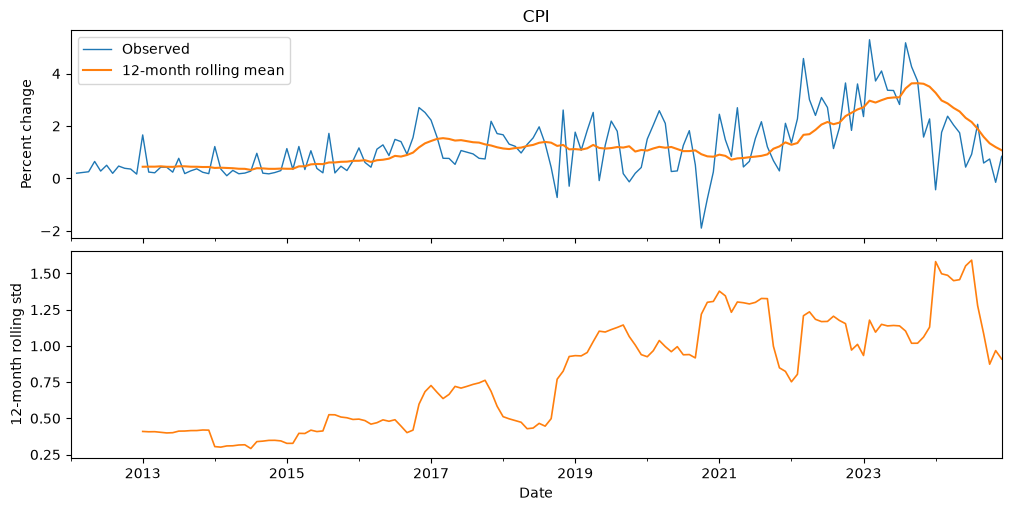

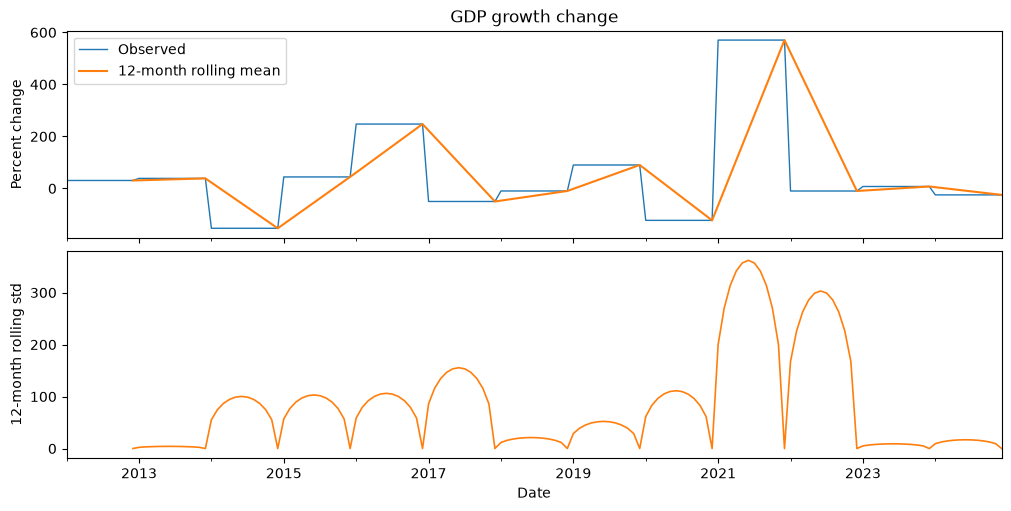

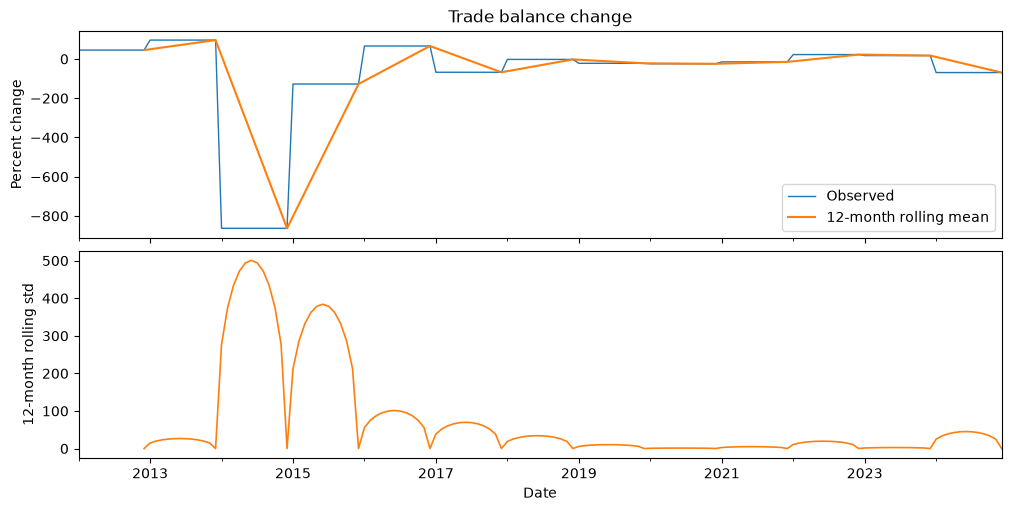

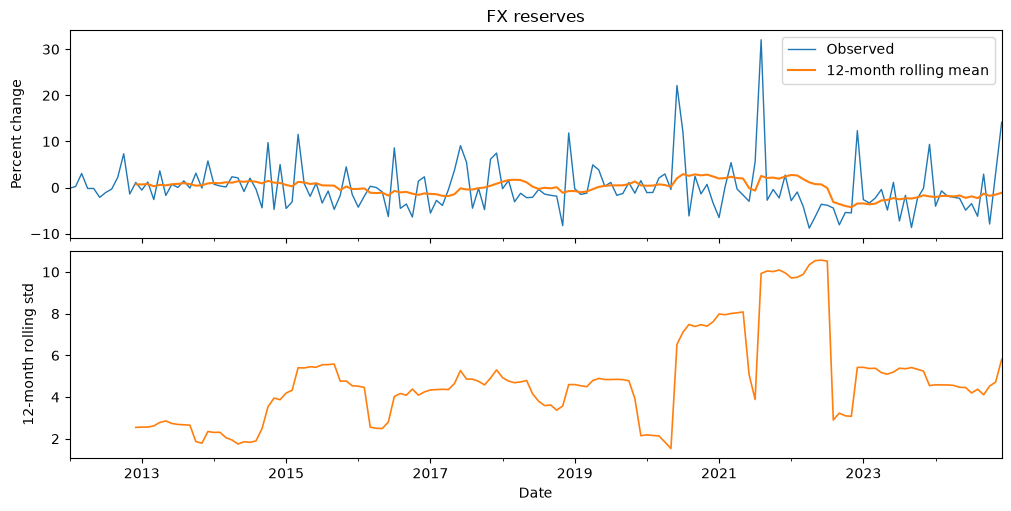

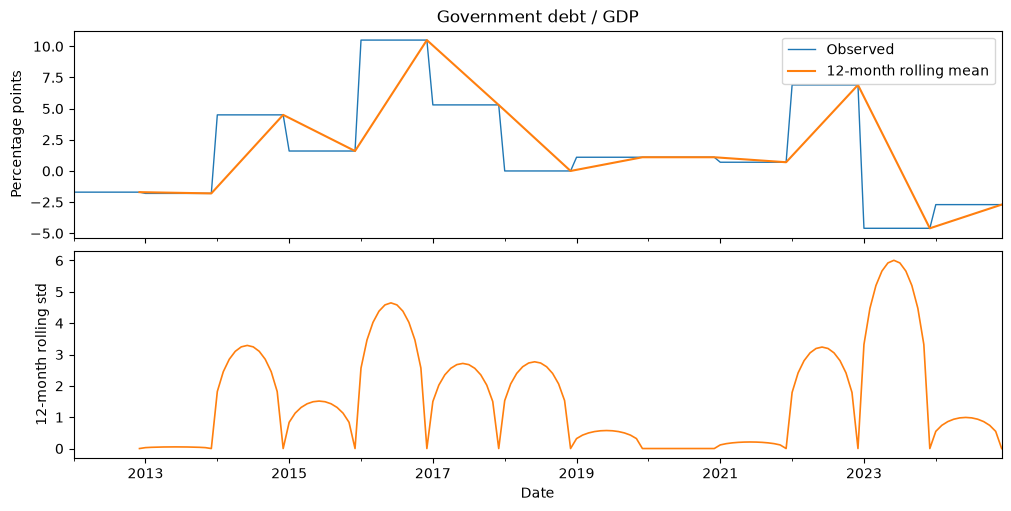

In [3]:
ROLLING_WINDOW = 12
rolling = monthly_data.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW)
rolling_mean = rolling.mean()
rolling_std = rolling.std(ddof=1)

for name in monthly_data:
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, layout="constrained")
    monthly_data[name].plot(ax=axes[0], label="Observed", linewidth=1)
    rolling_mean[name].plot(ax=axes[0], label="12-month rolling mean", linewidth=1.5)
    unit = "Percentage points" if name == "Government debt / GDP" else "Percent change"
    axes[0].set(title=name, ylabel=unit)
    axes[0].legend()
    rolling_std[name].plot(ax=axes[1], color="tab:orange", linewidth=1.2)
    axes[1].set(xlabel="Date", ylabel="12-month rolling std")
    plt.show()

下面汇总五个因子的均值、中位数、最大值、最小值和标准差。统计范围为上述训练期的月度输入；缺失值跳过；标准差使用样本标准差。

The following summarizes the mean, median, maximum, minimum and standard deviation of the five factors. The statistical range is the monthly input during the aforementioned training period; missing values are skipped; the standard deviation uses the sample standard deviation.

In [4]:
summary_statistics = monthly_data.agg(["mean", "median", "max", "min", "std"]).T
display(summary_statistics)

,mean,median,max,min,std
CPI,1.23215,0.97041,5.28666,-1.89419,1.17318
GDP growth change,50.6362,7.46143,570.488,-153.296,177.697
Trade balance change,-72.671,-15,96.1931,-862.944,236.017
FX reserves,-0.008613,-0.736422,32.0542,-8.79579,5.31209
Government debt / GDP,1.60769,1.1,10.5,-4.6,4.05748


下面对当前变化序列执行 ADF 和 KPSS 检验，列出统计量、p 值、选阶和原假设拒绝标记。GDP、贸易差额和政府债务按年各取一个值，其余因子使用非缺失的月度观测。
The following summarizes the mean, median, maximum, minimum, and standard deviation of the five factors. Next, run ADF and KPSS tests on the current change series, reporting the test statistic, p-value, selected lag order, and null-hypothesis rejection flag. GDP, trade balance, and government debt use one value per year; the remaining factors use non-missing monthly observations.


设置与假设：
- `alpha=0.05`；两项检验均含常数项（`regression="c"`）。
- ADF 原假设为存在单位根；月度最大滞后为 12，年度为 1，使用 AIC 选阶。
- KPSS 原假设为水平平稳；使用 `nlags="auto"`，超出查表范围的 p 值显示为 `< 0.01` 或 `> 0.10`。
- 检验沿用 2012–2024 年训练期；不追加差分。

Settings & const:
- `alpha = 0.05`; both tests include a constant term (`regression="c"`).
- ADF null hypothesis: unit root exists. Maximum lag is 12 for monthly data and 1 for annual data, with lag selection by AIC.
- KPSS null hypothesis: level stationarity. Use `nlags="auto"`; p-values outside the lookup range are displayed as `< 0.01` or `> 0.10`.
- Tests use the 2012–2024 training period; no additional differencing is applied. The statistical scope is the monthly input over the above training period; missing values are skipped; standard deviation uses the sample standard deviation (`ddof=1`).

In [ ]:
# setttings and constants
ALPHA = 0.05
REGRESSION = "c"
ADF_MAXLAG_MONTHLY, ADF_MAXLAG_ANNUAL = 12, 1
ADF_AUTOLAG, KPSS_NLAGS = "AIC", "auto"

rows = []
for name in monthly_data:
    values = monthly_data[name]
    annual = name in ANNUAL
    if annual:
        # Use one observation per year for repeated annual factors.
        values = values.groupby(values.index.year).first()
    values = values.dropna()
    maxlag = ADF_MAXLAG_ANNUAL if annual else ADF_MAXLAG_MONTHLY
    adf = adfuller(values, maxlag=maxlag, regression=REGRESSION,
                  autolag=ADF_AUTOLAG, result_object=True)
    with warnings.catch_warnings():
        # Report KPSS bounds in the table instead of repeating warnings.
        warnings.simplefilter("ignore", InterpolationWarning)
        kp = kpss(values, regression=REGRESSION, nlags=KPSS_NLAGS, result_object=True)
    if kp.statistic < kp.critical_values["10%"]:
        kp_p = "> 0.10"
    elif kp.statistic > kp.critical_values["1%"]:
        kp_p = "< 0.01"
    else:
        kp_p = f"{kp.pvalue:.6g}"
    rows.append({
        "factor": name, "frequency": "annual" if annual else "monthly", "n": len(values),
        "ADF_stat": adf.statistic, "ADF_p": adf.pvalue, "ADF_lags": adf.lags,
        "ADF_reject_unit_root": adf.pvalue < ALPHA,
        "KPSS_stat": kp.statistic, "KPSS_p": kp_p, "KPSS_lags": kp.lags,
        "KPSS_reject_stationarity": kp.statistic > kp.critical_values[f"{100 * ALPHA:g}%"],
    })
unit_root_results = pd.DataFrame(rows).set_index("factor")
display(unit_root_results)

,frequency,n,ADF_stat,ADF_p,ADF_lags,ADF_reject_unit_root,KPSS_stat,KPSS_p,KPSS_lags,KPSS_reject_stationarity
factor,,,,,,,,,,
CPI,monthly,155,-1.73222,0.414592,12,False,0.986326,< 0.01,7,True
GDP growth change,annual,13,-4.46441,0.000227903,0,True,0.252842,> 0.10,4,False
Trade balance change,annual,13,-3.44364,0.00955809,0,True,0.141148,> 0.10,0,False
FX reserves,monthly,156,-11.2616,1.61718e-20,0,True,0.20318,> 0.10,0,False
Government debt / GDP,annual,13,-2.82413,0.054909,0,False,0.172444,> 0.10,0,False


**结果分析 / Analysis**

在单位根检验当中，CPI数据的ADF没有reject单位根，而KPSS检验reject了数据的平稳性。不过结合CPI MoM% 数据与前面的图便可以发现，导致两个检验判断不平稳的主要原因是2021年到2023年的CPI月度变化的加速的情况。对于月度CPI变化值，通常很难出现连续的上涨的趋势，而24年之后的数据也说明不存在长期的趋势，因此可以归类为：带有结构断点的平稳序列，也就是包含异常值的平稳序列。

In the unit root tests, the ADF test for CPI data did not reject the unit root, while the KPSS test rejected stationarity. However, combining the CPI MoM% data with the earlier figures shows that the main reason both tests indicate non-stationarity is the acceleration in monthly CPI changes from 2021 to 2023. For monthly CPI changes, sustained upward trends are usually difficult to observe, and the data after 2024 also indicate that there is no long-term trend. Therefore, it can be classified as a stationary series with structural breaks, that is, a stationary series containing outliers.


因为检验单位根的目的是防止伪回归，而CPI月度变化值数据并没有长期的趋势（部分数据集的异常值/脉冲），因此直接将此数据放入随后的回归当中不会导致传统意义上的伪回归，后续将继续回归。

Since the purpose of unit root testing is to prevent spurious regression, and the monthly CPI change data do not have a long-term trend (only outliers/impulses in some datasets), directly including this data in the subsequent regression will not cause conventional spurious regression. The regression will therefore proceed.